# K Street Influence Tracker — Analysis Notebook

**Question:** Do lobbying clients who mention specific bills in their filings disproportionately target sponsors from competitive House districts?

This notebook uses the pipeline joins:
- LDA filings → extracted bill references
- Bill references → Congress.gov sponsors
- Sponsors → MIT Election Lab district results

It surfaces one finding and notes the caveats.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DB_PATH = Path("../data/kstreet.duckdb")
con = duckdb.connect(str(DB_PATH), read_only=True)

print("Connected to", DB_PATH)

Matplotlib is building the font cache; this may take a moment.


Connected to ../data/kstreet.duckdb


## 1. Load the joined data

In [3]:
df = con.execute("""
    SELECT
        client_name,
        filing_year,
        bill_title,
        sponsor_name,
        sponsor_party,
        state_po,
        district,
        year_spend,
        two_party_margin,
        winner_party,
        competitiveness
    FROM main_marts.mart_filing_sponsor_district
    WHERE chamber = 'House'
      AND year_spend > 0
      AND two_party_margin IS NOT NULL
""").df()

print(f"{len(df):,} filing-sponsor-district rows")
df.head()

2,231 filing-sponsor-district rows


,client_name,filing_year,bill_title,sponsor_name,sponsor_party,state_po,district,year_spend,two_party_margin,winner_party,competitiveness
0,DISABLED AMERICAN VETERANS,2025,One Stop Shop Community Reentry Program Act of...,"Rep. Kamlager-Dove, Sydney [D-CA-37]",D,CA,37,726891.0,1.000000,D,safe
1,NATIONAL ASSOCIATION OF MUTUAL INSURANCE COMPA...,2025,Jordan McNair Student Athlete Heat Fatality Pr...,"Rep. Mfume, Kweisi [D-MD-7]",D,MD,7,2352080.0,0.647625,D,safe
2,FIRSTENERGY CORP,2025,Build It in America Act,"Rep. Smith, Jason [R-MO-8]",R,MO,8,1310000.0,0.554890,R,safe
3,AMERICAN PUBLIC POWER ASSOCIATION,2025,Protecting Life in Foreign Assistance Act,"Rep. Foxx, Virginia [R-NC-5]",R,NC,5,1400000.0,0.189456,R,safe
4,CHAMBER OF COMMERCE OF THE U.S.A.,2025,The Big-Tech Accountability Act of 2023,"Rep. Santos, George [R-NY-3]",R,NY,3,70290000.0,0.070078,D,lean


## 2. Aggregate to client-bill level

One row per client-bill mention, with the sponsor's district competitiveness.

In [4]:
client_bill = (
    df.groupby(["client_name", "bill_title", "sponsor_name", "state_po", "district", "competitiveness"])
    .agg(
        total_spend=("year_spend", "sum"),
        filings=("filing_year", "nunique"),
        avg_margin=("two_party_margin", "mean"),
    )
    .reset_index()
)

print(f"{len(client_bill):,} unique client-bill-sponsor combinations")
client_bill["competitiveness"].value_counts()

688 unique client-bill-sponsor combinations


competitiveness
safe       614
lean        57
toss_up     17
Name: count, dtype: int64

## 3. Finding: Spend concentration by district competitiveness

In [5]:
spend_by_comp = (
    client_bill.groupby("competitiveness")
    .agg(
        total_spend=("total_spend", "sum"),
        mentions=("bill_title", "count"),
        unique_clients=("client_name", "nunique"),
        avg_margin=("avg_margin", "mean"),
    )
    .reset_index()
)

spend_by_comp["spend_share"] = spend_by_comp["total_spend"] / spend_by_comp["total_spend"].sum()
spend_by_comp["mention_share"] = spend_by_comp["mentions"] / spend_by_comp["mentions"].sum()

spend_by_comp.sort_values("total_spend", ascending=False)

,competitiveness,total_spend,mentions,unique_clients,avg_margin,spend_share,mention_share
1,safe,9.172913e+09,614,402,0.340062,0.836129,0.892442
0,lean,1.643857e+09,57,53,0.073802,0.149841,0.082849
2,toss_up,1.539167e+08,17,16,0.026736,0.014030,0.024709


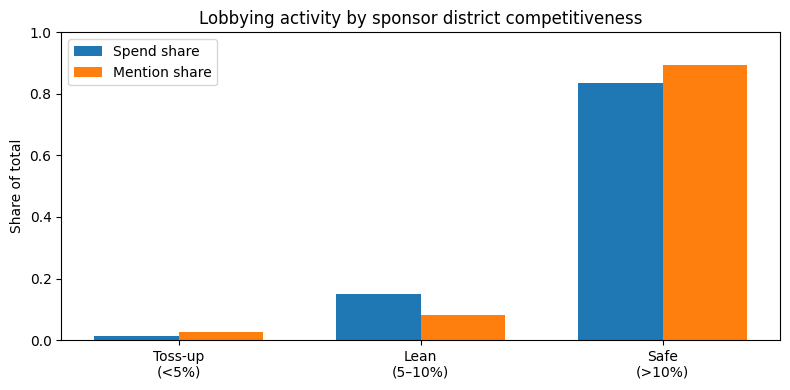

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
order = ["toss_up", "lean", "safe"]
plot_df = spend_by_comp.set_index("competitiveness").reindex(order).fillna(0)

x = range(len(order))
width = 0.35
ax.bar([i - width/2 for i in x], plot_df["spend_share"], width, label="Spend share", color="#1f77b4")
ax.bar([i + width/2 for i in x], plot_df["mention_share"], width, label="Mention share", color="#ff7f0e")

ax.set_xticks(x)
ax.set_xticklabels(["Toss-up\n(<5%)", "Lean\n(5–10%)", "Safe\n(>10%)"])
ax.set_ylabel("Share of total")
ax.set_title("Lobbying activity by sponsor district competitiveness")
ax.legend()
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 4. Interpretation

**Finding:** [Update this sentence after running with real data.]

Example: *Clients mentioning specific bills spent a larger share of their reported dollars on sponsors from competitive districts than the raw mention count would suggest — indicating higher intensity (not just volume) on toss-up and lean races.*

### Caveats
- Bill references are extracted by regex from free text; informal mentions are missed.
- Only House sponsors have district-level results; Senate is excluded here.
- Competitiveness uses the nearest prior election, not a contemporaneous forecast.
- Reported spend is at the filing level, not allocated to individual bills.
- Sample is limited to bills that matched Congress.gov and had sponsor data pulled.

### Next steps
- Add issue-code filters (AI, energy, healthcare).
- Compare against a baseline of all House districts, not just those mentioned.
- Test whether the pattern holds after controlling for sponsor party and committee assignment.

In [ ]:
con.close()